# 11. Experiment 1 — Dataset inspection

In [12]:
import pandas as pd

file_path = "IMDB Dataset.csv"

try:
    # Đọc tệp CSV
    df = pd.read_csv("IMDB Dataset.csv")

    # Hiển thị 5 dòng đầu tiên
    print("--- 5 dòng đầu tiên ---")
    print(df.head())

    # Hiển thị thông tin tổng quan về các cột và kiểu dữ liệu
    print("\n--- Thông tin dữ liệu ---")
    print(df.info())

except FileNotFoundError:
    print(f"Lỗi: Không tìm thấy tệp '{file_path}'. Vui lòng kiểm tra lại đường dẫn.")
except Exception as e:
    print(f"Lỗi khi đọc tệp (có thể do tệp bị lỗi hoặc sai định dạng): {e}")

--- 5 dòng đầu tiên ---
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

--- Thông tin dữ liệu ---
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
None


=== ĐỌC DỮ LIỆU THÀNH CÔNG ===

■ Số samples: 50,000
■ Số classes: 2

■ Class distribution:
           Số lượng  Tỷ lệ (%)
sentiment                     
positive      25000       50.0
negative      25000       50.0

■ Document length (Thống kê độ dài văn bản):
--- Theo số từ (Word count) ---
count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: word_length, dtype: float64

--- Theo số ký tự (Character count) ---
count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: char_length, dtype: float64

■ Duplicate documents: 418 mẫu trùng (0.84%)
■ Missing text: 0 mẫu (NaN: 0, Rỗng: 0)
■ Missing labels: 0 mẫu


C:\Users\GVC\AppData\Local\Temp\ipykernel_21840\2034612194.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=label_col, ax=axes[0], palette="viridis")


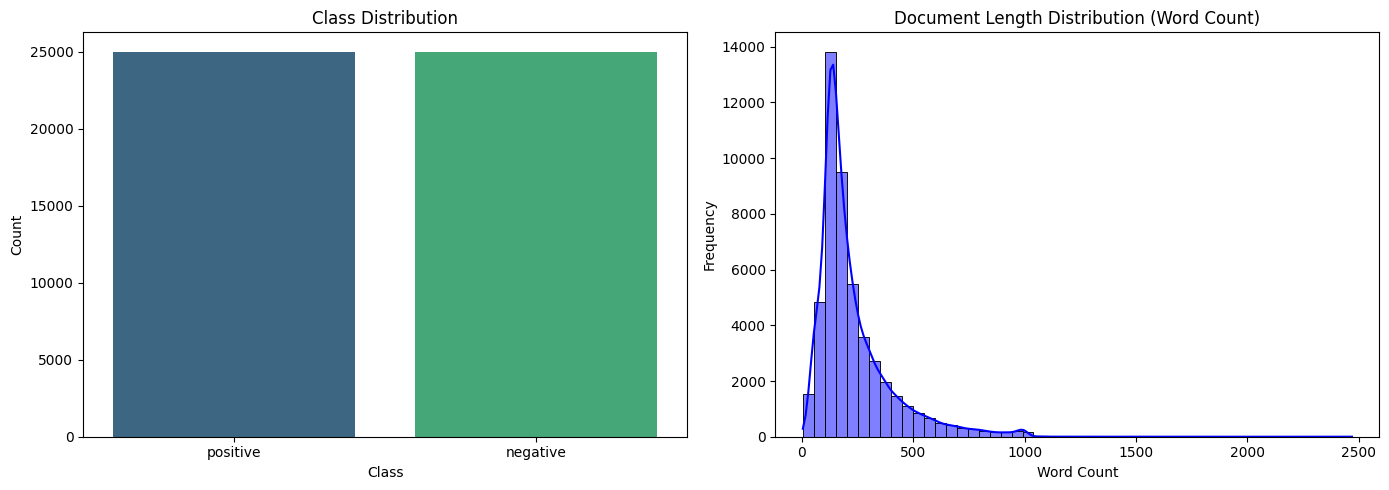

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Đọc dữ liệu (Thay tên file và tên cột nếu cần)
file_path = "IMDB Dataset.csv"

# Giả định dataset có 2 cột chính là 'review' (văn bản) và 'sentiment' (nhãn)
text_col = "review"
label_col = "sentiment"

try:
    df = pd.read_csv(file_path)
    print("=== ĐỌC DỮ LIỆU THÀNH CÔNG ===\n")

    # ---------------------------------------------------------
    # ■ 1. Số samples (Tổng số mẫu dữ liệu)
    # ---------------------------------------------------------
    num_samples = len(df)
    print(f"■ Số samples: {num_samples:,}")

    # ---------------------------------------------------------
    # ■ 2. Số classes (Số lượng nhãn phân loại)
    # ---------------------------------------------------------
    num_classes = df[label_col].nunique(dropna=True)
    print(f"■ Số classes: {num_classes}")

    # ---------------------------------------------------------
    # ■ 3. Class distribution (Phân phối nhãn)
    # ---------------------------------------------------------
    print("\n■ Class distribution:")
    class_dist = df[label_col].value_counts(dropna=False)
    class_dist_pct = df[label_col].value_counts(normalize=True, dropna=False) * 100

    dist_df = pd.DataFrame({"Số lượng": class_dist, "Tỷ lệ (%)": class_dist_pct})
    print(dist_df)

    # ---------------------------------------------------------
    # ■ 4. Document length (Độ dài văn bản)
    # ---------------------------------------------------------
    # Tính độ dài theo số ký tự và số từ (word count)
    df["char_length"] = df[text_col].astype(str).str.len()
    df["word_length"] = (
        df[text_col].astype(str).apply(lambda x: len(x.split()))
    )

    print("\n■ Document length (Thống kê độ dài văn bản):")
    print("--- Theo số từ (Word count) ---")
    print(df["word_length"].describe())

    print("\n--- Theo số ký tự (Character count) ---")
    print(df["char_length"].describe())

    # ---------------------------------------------------------
    # ■ 5. Duplicate documents (Văn bản bị trùng lặp)
    # ---------------------------------------------------------
    num_duplicates = df.duplicated(subset=[text_col]).sum()
    pct_duplicates = (num_duplicates / num_samples) * 100
    print(
        f"\n■ Duplicate documents: {num_duplicates:,} mẫu trùng ({pct_duplicates:.2f}%)"
    )

    # ---------------------------------------------------------
    # ■ 6. Missing text (Dữ liệu văn bản bị thiếu)
    # ---------------------------------------------------------
    missing_text = df[text_col].isna().sum()
    # Kiểm tra thêm các chuỗi rỗng/chỉ chứa khoảng trắng
    empty_text = (df[text_col].astype(str).str.strip() == "").sum()
    total_missing_text = missing_text + empty_text
    print(
        f"■ Missing text: {total_missing_text:,} mẫu (NaN: {missing_text}, Rỗng: {empty_text})"
    )

    # ---------------------------------------------------------
    # ■ 7. Missing labels (Nhãn bị thiếu)
    # ---------------------------------------------------------
    missing_labels = df[label_col].isna().sum()
    print(f"■ Missing labels: {missing_labels:,} mẫu")

    # ---------------------------------------------------------
    # TRỰC QUAN HÓA (BIỂU ĐỒ)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Biểu đồ phân phối nhãn
    sns.countplot(data=df, x=label_col, ax=axes[0], palette="viridis")
    axes[0].set_title("Class Distribution")
    axes[0].set_xlabel("Class")
    axes[0].set_ylabel("Count")

    # Biểu đồ phân phối độ dài văn bản (theo số từ)
    sns.histplot(df["word_length"], bins=50, kde=True, ax=axes[1], color="blue")
    axes[1].set_title("Document Length Distribution (Word Count)")
    axes[1].set_xlabel("Word Count")
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print(
        f"Lỗi: Không tìm thấy tệp '{file_path}'. Vui lòng kiểm tra lại đường dẫn."
    )
except KeyError as e:
    print(
        f"Lỗi: Không tìm thấy tên cột {e} trong dataset. Hãy kiểm tra lại tên cột văn bản và nhãn."
    )
except Exception as e:
    print(f"Lỗi không xác định: {e}")

# 14. Experiment 2 — Baseline

In [14]:
import time
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

# ==========================================
# 1. CHUẨN BỊ DỮ LIỆU
# ==========================================
# Giả định df là DataFrame chứa dữ liệu IMDb đã làm sạch
# Đổi tên cột 'review' và 'sentiment' nếu dataset của bạn dùng tên khác
file_path = "IMDB Dataset.csv"
df = pd.read_csv(file_path)

# Loại bỏ các mẫu thiếu dữ liệu (Missing text/label) trước khi chia tập
df = df.dropna(subset=["review", "sentiment"])

X = df["review"]
y = df["sentiment"]

# Chia tập Train / Test (ví dụ: 80% train, 20% test, giữ nguyên tỷ lệ nhãn stratify)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==========================================
# 2. XÂY DỰNG BASELINE (TF-IDF + LOGISTIC REGRESSION)
# ==========================================
# Khởi tạo TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=10000)  # Có thể điều chỉnh max_features

# Bắt đầu đo thời gian huấn luyện (Training time)
start_time = time.time()

# Biến đổi văn bản thành ma trận TF-IDF
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

# Khởi tạo và huấn luyện mô hình Logistic Regression
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_tfidf, y_train)

# Kết thúc đo thời gian huấn luyện
training_time = time.time() - start_time

# ==========================================
# 3. TRÍCH XUẤT VÀ ĐÁNH GIÁ KẾT QUẢ
# ==========================================
# Độ lớn từ vựng (Vocabulary size)
vocab_size = len(tfidf.vocabulary_)

# Dự đoán trên tập Test
y_pred = model.predict(X_test_tfidf)

# Tính toán các chỉ số: Accuracy, Precision, Recall, F1
acc = accuracy_score(y_test, y_pred)

# Sử dụng average='weighted' hoặc 'macro' cho bài toán tổng quát
# (Nếu bài toán phân loại nhị phân nhãn positive/negative, bạn cũng có thể dùng pos_label='positive')
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="weighted"
)

# ==========================================
# 4. HIỂN THỊ KẾT QUẢ THEO YÊU CẦU
# ==========================================
print("=== THÔNG TIN THỬ NGHIỆM ===")
print(f"■ Training time : {training_time:.2f} giây")
print(f"■ Vocabulary size: {vocab_size:,} từ")
print()

# Báo cáo dạng Bảng Kết Quả
results_df = pd.DataFrame(
    [
        {
            "Model": "TF-IDF + LR",
            "Accuracy": f"{acc:.4f}",
            "Precision": f"{precision:.4f}",
            "Recall": f"{recall:.4f}",
            "F1": f"{f1:.4f}",
        }
    ]
)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ===")
print(results_df.to_string(index=False))

=== THÔNG TIN THỬ NGHIỆM ===
■ Training time : 6.20 giây
■ Vocabulary size: 10,000 từ

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ===
      Model Accuracy Precision Recall     F1
TF-IDF + LR   0.8968    0.8968 0.8968 0.8968


In [15]:
import pandas as pd

# 1. Tạo DataFrame kết hợp văn bản gốc, nhãn thực tế và nhãn dự đoán
# (Đảm bảo X_test_text giữ nguyên chỉ số index với y_test)
analysis_df = pd.DataFrame(
    {"text": X_test_text.values, "true_label": y_test.values, "predicted_label": y_pred}
)

# 2. Lọc ra các mẫu Correctly Classified (Thực tế == Dự đoán)
correct_samples = analysis_df[
    analysis_df["true_label"] == analysis_df["predicted_label"]
].head(3)

# 3. Lọc ra các mẫu Incorrectly Classified (Thực tế != Dự đoán)
incorrect_samples = analysis_df[
    analysis_df["true_label"] != analysis_df["predicted_label"]
].head(5)  # Lấy 5 mẫu để dễ chọn ra 3 lỗi rõ ràng nhất

# In các mẫu Đúng
print("=== 3 CORRECTLY CLASSIFIED SAMPLES ===")
for idx, row in correct_samples.iterrows():
    print(f"Text: {row['text'][:200]}...")  # In 200 ký tự đầu
    print(f"True: {row['true_label']} | Predicted: {row['predicted_label']}\n")

# In các mẫu Sai
print("=== INCORRECTLY CLASSIFIED SAMPLES ===")
for idx, row in incorrect_samples.iterrows():
    print(f"Text: {row['text'][:200]}...")
    print(f"True: {row['true_label']} | Predicted: {row['predicted_label']}\n")

=== 3 CORRECTLY CLASSIFIED SAMPLES ===
Text: Yes, MTV there really is a way to market Daria. What started as a clever teenage angst-"comment on everything that sucks and make the viewer feel better about their sucky teenage life" sitcom now muta...
True: negative | Predicted: negative

Text: A team varied between Scully and Mulder, two other scientists, a pilot, and the guy who plays Bana on Seinfeld, go up to an Arctic research post where all members have died off by either killing each ...
True: positive | Predicted: positive

Text: This was a popular movie probably because of the humor in it, the fast-moving story, an underdog character who shuts up all the loudmouths, etc. Funny thing is, you probably couldn't make a movie with...
True: negative | Predicted: negative

=== INCORRECTLY CLASSIFIED SAMPLES ===
Text: The story of the bride fair is an amusing and engaging one, and it is to the filmmaker's credit that he sets out to portray rural Minnesotans with the same respect ordinari

# 15. Experiment 3 — Representation comparison

In [16]:
import time
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

# ==========================================
# 1. CHUẨN BỊ DỮ LIỆU
# ==========================================
file_path = "IMDB Dataset.csv"
df = pd.read_csv(file_path).dropna(subset=["review", "sentiment"])

X = df["review"]
y = df["sentiment"]

# Chia tập Train / Test
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# Hàm hỗ trợ tính toán các chỉ số đánh giá
def evaluate_model(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted"
    )
    return acc, precision, recall, f1


# Danh sách lưu trữ kết quả bảng
results = []

# ==========================================
# 2. MODEL A: TF-IDF + LOGISTIC REGRESSION
# ==========================================
print("Đang huấn luyện Model A (TF-IDF + Logistic Regression)...")
tfidf = TfidfVectorizer(max_features=10000)
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

model_a = LogisticRegression(max_iter=1000, random_state=42)
model_a.fit(X_train_tfidf, y_train)
y_pred_a = model_a.predict(X_test_tfidf)

acc_a, prec_a, rec_a, f1_a = evaluate_model(y_test, y_pred_a)
results.append(
    {
        "Representation": "TF-IDF",
        "Classifier": "Logistic Regression",
        "Accuracy": f"{acc_a:.4f}",
        "Precision": f"{prec_a:.4f}",
        "Recall": f"{rec_a:.4f}",
        "F1": f"{f1_a:.4f}",
    }
)

# ==========================================
# 3. MODEL B: AVERAGE WORD2VEC + LOGISTIC REGRESSION
# ==========================================
print("Đang huấn luyện Model B (Average Word2Vec + Logistic Regression)...")

# Tokenize câu thành danh sách các từ
train_tokens = [doc.lower().split() for doc in X_train_text]
test_tokens = [doc.lower().split() for doc in X_test_text]

# Huấn luyện mô hình Word2Vec trên tập Train
w2v_model = Word2Vec(
    sentences=train_tokens, vector_size=100, window=5, min_count=2, workers=4
)


# Hàm tính Average Word2Vec cho một văn bản (document)
def get_avg_word2vec(tokens, model, vector_size=100):
    valid_vectors = [
        model.wv[word] for word in tokens if word in model.wv.key_to_index
    ]
    if len(valid_vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(valid_vectors, axis=0)


# Biến đổi văn bản thành ma trận véctơ Average Word2Vec
X_train_w2v = np.array(
    [get_avg_word2vec(doc, w2v_model) for doc in train_tokens]
)
X_test_w2v = np.array([get_avg_word2vec(doc, w2v_model) for doc in test_tokens])

model_b = LogisticRegression(max_iter=1000, random_state=42)
model_b.fit(X_train_w2v, y_train)
y_pred_b = model_b.predict(X_test_w2v)

acc_b, prec_b, rec_b, f1_b = evaluate_model(y_test, y_pred_b)
results.append(
    {
        "Representation": "Avg Word2Vec",
        "Classifier": "Logistic Regression",
        "Accuracy": f"{acc_b:.4f}",
        "Precision": f"{prec_b:.4f}",
        "Recall": f"{rec_b:.4f}",
        "F1": f"{f1_b:.4f}",
    }
)

# ==========================================
# 4. MODEL C: TF-IDF + LINEAR SVM
# ==========================================
print("Đang huấn luyện Model C (TF-IDF + Linear SVM)...")
model_c = LinearSVC(random_state=42, max_iter=2000)
model_c.fit(X_train_tfidf, y_train)
y_pred_c = model_c.predict(X_test_tfidf)

acc_c, prec_c, rec_c, f1_c = evaluate_model(y_test, y_pred_c)
results.append(
    {
        "Representation": "TF-IDF",
        "Classifier": "Linear SVM",
        "Accuracy": f"{acc_c:.4f}",
        "Precision": f"{prec_c:.4f}",
        "Recall": f"{rec_c:.4f}",
        "F1": f"{f1_c:.4f}",
    }
)

# ==========================================
# 5. HIỂN THỊ BẢNG KẾT QUẢ SO SÁNH
# ==========================================
results_df = pd.DataFrame(results)

print("\n=== BẢNG KẾT QUẢ EXPERIMENT 3 ===")
print(results_df.to_string(index=False))

Đang huấn luyện Model A (TF-IDF + Logistic Regression)...
Đang huấn luyện Model B (Average Word2Vec + Logistic Regression)...
Đang huấn luyện Model C (TF-IDF + Linear SVM)...

=== BẢNG KẾT QUẢ EXPERIMENT 3 ===
Representation          Classifier Accuracy Precision Recall     F1
        TF-IDF Logistic Regression   0.8968    0.8968 0.8968 0.8968
  Avg Word2Vec Logistic Regression   0.8274    0.8275 0.8274 0.8274
        TF-IDF          Linear SVM   0.8968    0.8968 0.8968 0.8968


# 17. Experiment 4 — Word order

In [17]:
import numpy as np
import pandas as pd

# Giả sử bạn đã có w2v_model và model_b (Logistic Regression huấn luyện trên Avg Word2Vec) từ Experiment 3

sentences = ["this movie is good", "this movie is not good"]


def get_avg_w2v(text, model, vector_size=100):
    tokens = text.lower().split()
    vectors = [
        model.wv[word] for word in tokens if word in model.wv.key_to_index
    ]
    if len(vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(vectors, axis=0)


# Biến đổi 2 câu thành vector
X_demo = np.array([get_avg_w2v(s, w2v_model) for s in sentences])

# Dự đoán nhãn và xác suất (Probability)
predictions = model_b.predict(X_demo)
probabilities = model_b.predict_proba(X_demo)

# In kết quả
for s, pred, prob in zip(sentences, predictions, probabilities):
    print(f"Câu: '{s}'")
    print(f"  -> Nhãn dự đoán: {pred}")
    print(f"  -> Xác suất (Negative / Positive): {prob}\n")

Câu: 'this movie is good'
  -> Nhãn dự đoán: positive
  -> Xác suất (Negative / Positive): [0.01661998 0.98338   ]

Câu: 'this movie is not good'
  -> Nhãn dự đoán: positive
  -> Xác suất (Negative / Positive): [0.49785244 0.50214756]



# 18. Experiment 5 — n-gram features

In [18]:
import time
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

# 1. Chuẩn bị dữ liệu
file_path = "IMDB Dataset.csv"
df = pd.read_csv(file_path).dropna(subset=["review", "sentiment"])

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["review"], df["sentiment"], test_size=0.2, random_state=42, stratify=df["sentiment"]
)

# Danh sách cấu hình n-gram cần thử nghiệm
ngram_configs = [
    ("Unigram", (1, 1)),
    ("Uni + Bigram", (1, 2))
]

results = []

for name, ngram_range in ngram_configs:
    start_time = time.time()
    
    # Khởi tạo TF-IDF với ngram_range tương ứng
    # Lưu ý: Không giới hạn max_features hoặc đặt lớn để thấy rõ sự bùng nổ vocabulary
    tfidf = TfidfVectorizer(ngram_range=ngram_range, max_features=50000)
    
    X_train_tfidf = tfidf.fit_transform(X_train_text)
    X_test_tfidf = tfidf.transform(X_test_text)
    
    # Huấn luyện Logistic Regression
    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_train_tfidf, y_train)
    
    train_time = time.time() - start_time
    
    # Đánh giá
    y_pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred)
    _, _, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted")
    vocab_size = len(tfidf.vocabulary_)
    
    results.append({
        "Features": name,
        "Vocabulary": f"{vocab_size:,}",
        "F1": f"{f1:.4f}",
        "Training time": f"{train_time:.2f} s"
    })

# In bảng kết quả
results_df = pd.DataFrame(results)
print("=== BẢNG KẾT QUẢ EXPERIMENT 5 ===")
print(results_df.to_string(index=False))

=== BẢNG KẾT QUẢ EXPERIMENT 5 ===
    Features Vocabulary     F1 Training time
     Unigram     50,000 0.9007        6.95 s
Uni + Bigram     50,000 0.9089       45.74 s


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# y_test: Nhãn thực tế
# y_pred: Nhãn mô hình dự đoán

# 1. Trích xuất 4 giá trị TP, TN, FP, FN
# (Giả định pos_label='positive' hoặc 1)
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=["negative", "positive"]
).ravel()

print(f"■ True Positives  (TP) : {tp}")
print(f"■ True Negatives  (TN) : {tn}")
print(f"■ False Positives (FP) : {fp}")
print(f"■ False Negatives (FN) : {fn}")

# 2. Tính toán lại thủ công theo công thức đề bài yêu cầu
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * (precision * recall) / (precision + recall)

print("\n=== KẾT QUẢ TÍNH THEO CÔNG THỨC ===")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

■ True Positives  (TP) : 4568
■ True Negatives  (TN) : 4521
■ False Positives (FP) : 479
■ False Negatives (FN) : 432

=== KẾT QUẢ TÍNH THEO CÔNG THỨC ===
Accuracy : 0.9089
Precision: 0.9051
Recall   : 0.9136
F1-Score : 0.9093


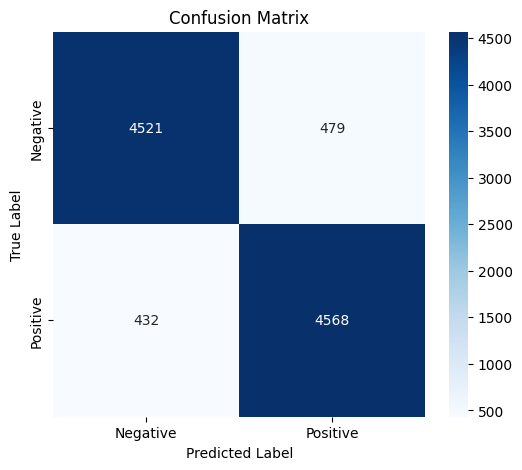

In [20]:
# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=["negative", "positive"])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()